<center><h1>Last_First_HW6</h1></center>

Name: Juifan Lin
<br>
Github Username: JiaLiiin
<br>
USC ID: 9985422205

## 1. Tree-Based Methods

Import packages

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_curve, auc, 
    roc_auc_score, accuracy_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb

### (a) Download the APS Failure data

In [4]:
train_df = pd.read_csv('../Data/aps_failure_training_set.csv', na_values='na', skiprows=20)
test_df = pd.read_csv('../Data/aps_failure_test_set.csv', na_values='na', skiprows=20)


train_df['class'] = train_df['class'].map({'neg': 0, 'pos': 1})
test_df['class'] = test_df['class'].map({'neg': 0, 'pos': 1})
X_train_raw = train_df.drop(columns=['class'])
y_train = train_df['class'].values
X_test_raw = test_df.drop(columns=['class'])
y_test = test_df['class'].values

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Univariate Imputation, simple and fast. Median is robust to heavy outliers.

Multivariate Feature Imputation, models each feature as function of others.

KNN Imputation, imputes missing values by weighted average of $k$ nearest instances, computationally expensive on 60000x170.

I will choose median imputation to be the optimal here given the high skewness and dimension size of 170 features.  

In [5]:
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns)

#### (ii) Calculate the coefficient of variation

In [7]:
s = X_train.std(ddof=1)
m = X_train.mean()

cv = (s / m).replace([np.inf, -np.inf], np.nan)
print(cv.sort_values(ascending=False))

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64


#### (iii) Plot a correlation matrix

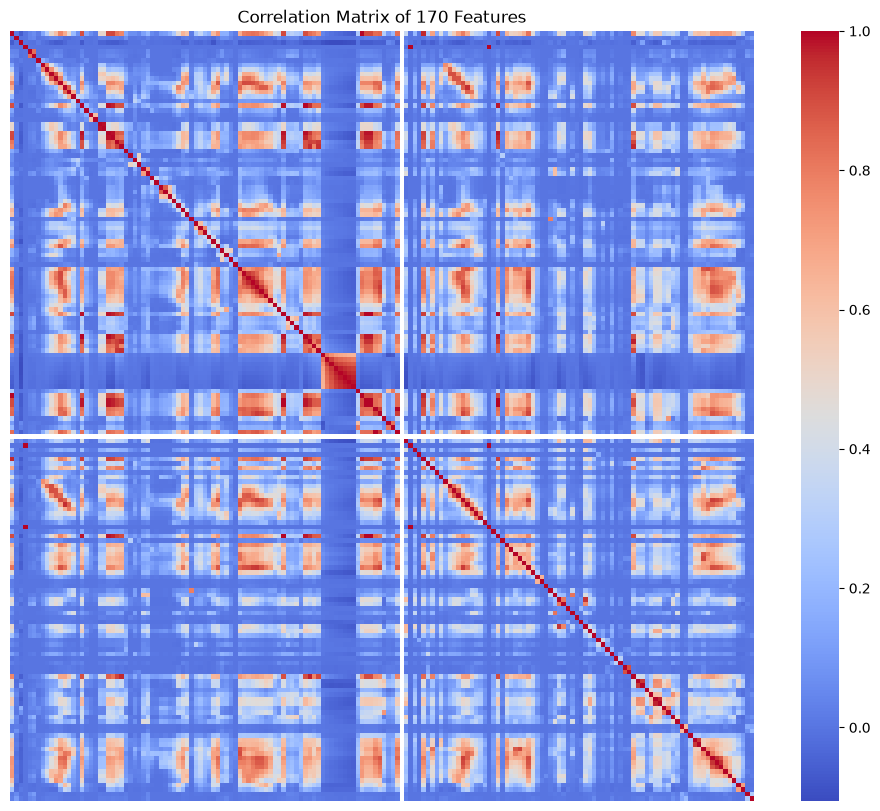

In [8]:
corr_matrix = X_train.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', cbar=True, xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix of 170 Features")
plt.show()

#### (iv) Make scatter plots and box plots

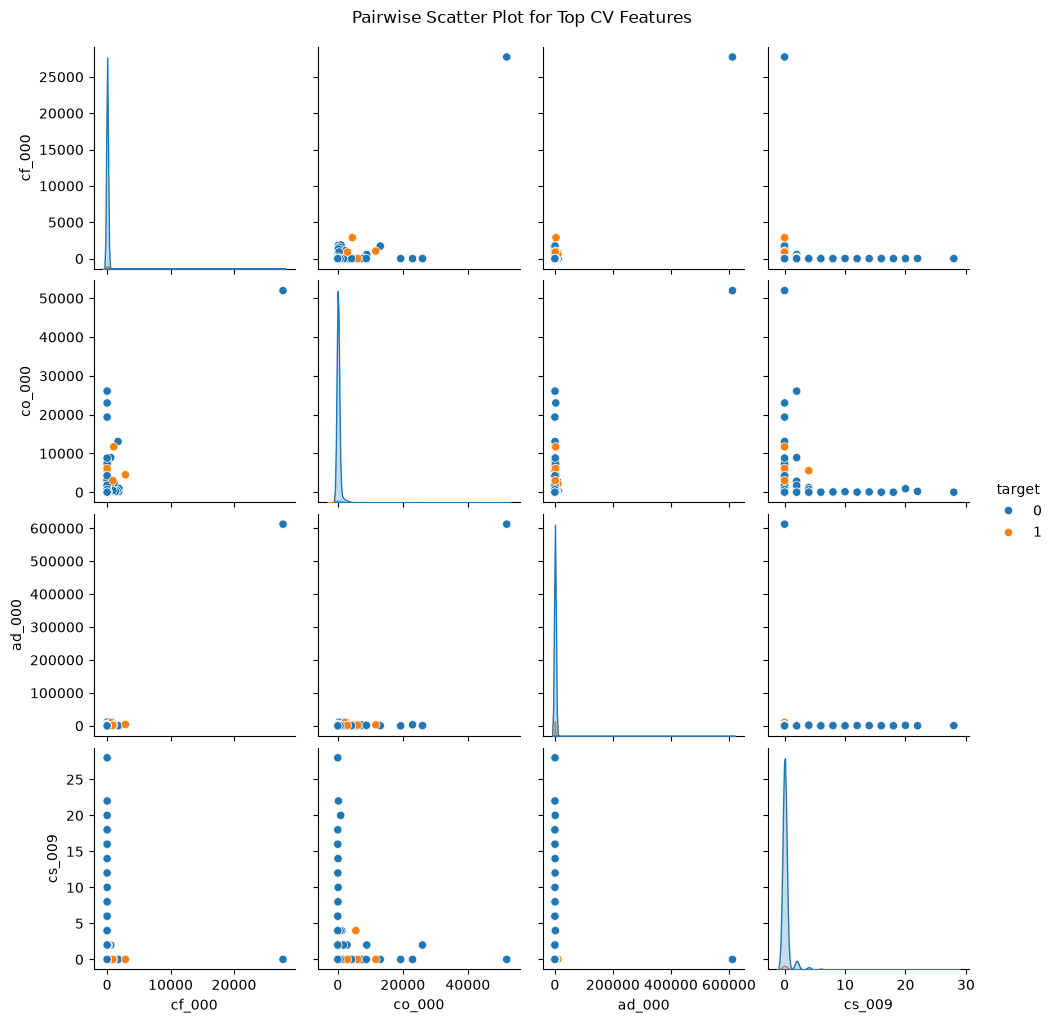

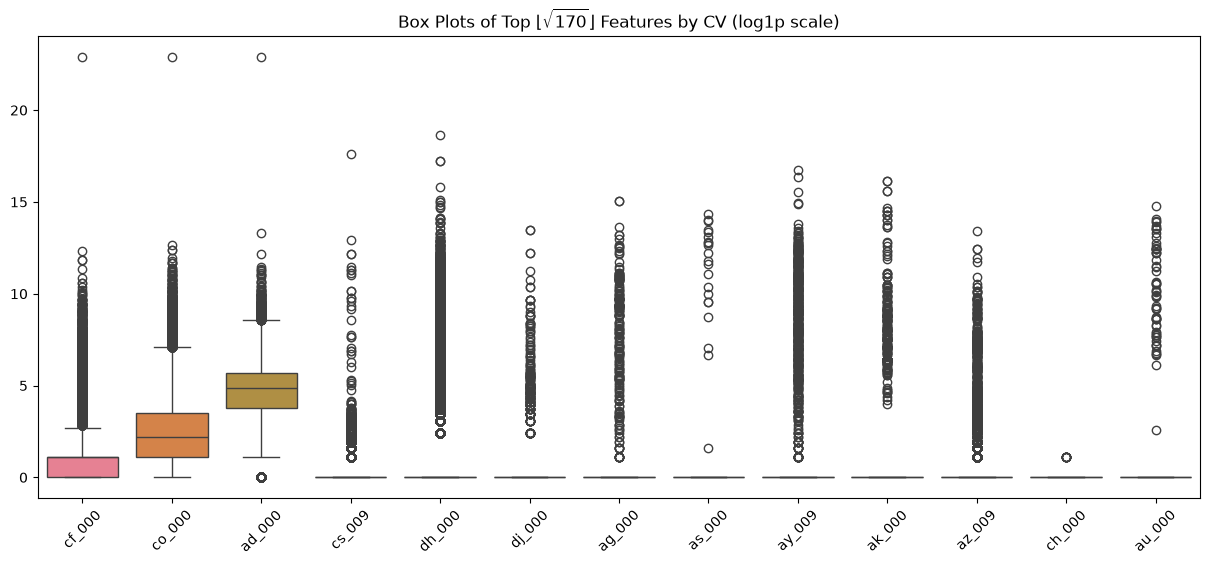

In [9]:
k = int(np.floor(np.sqrt(170)))
top_features = cv.sort_values(ascending=False).head(k).index.tolist()

sample_idx = np.random.choice(len(X_train), size=2000, replace=False)
sns.pairplot(X_train.loc[sample_idx, top_features[:4]].assign(target=y_train[sample_idx]), hue='target')
plt.suptitle("Pairwise Scatter Plot for Top CV Features", y=1.02)
plt.show()

plt.figure(figsize=(15, 6))
sns.boxplot(data=np.log1p(np.abs(X_train[top_features])))
plt.title(r"Box Plots of Top $\lfloor\sqrt{170}\rfloor$ Features by CV (log1p scale)")
plt.xticks(rotation=45)
plt.show()

No, because of extreme skewness, severe outliers, overlap between classes, and potential non-linear or multi-way interactions among high-dimensional features, just visual bivariate scatter plots are not enough to confirm statistical significance or predictive separation.

#### (v) Is this data set imbalanced?

In [10]:
neg_count, pos_count = np.bincount(y_train)
print(f"Negative: {neg_count}, Positive: {pos_count}, Ratio: {neg_count / pos_count:.1f}:1")

Negative: 59000, Positive: 1000, Ratio: 59.0:1


The dataset is heavily imbalanced 59000 negative vs 1000 positive, 59:1 ratio

### (c) Train a random forest

Train Confusion Matrix:
 [[59000     0]
 [    1   999]]
Test Confusion Matrix:
 [[15610    15]
 [  106   269]]
Train Misclassification Error: 0.0000
Test Misclassification Error: 0.0076
Train AUC: 1.0000
Test AUC: 0.9927


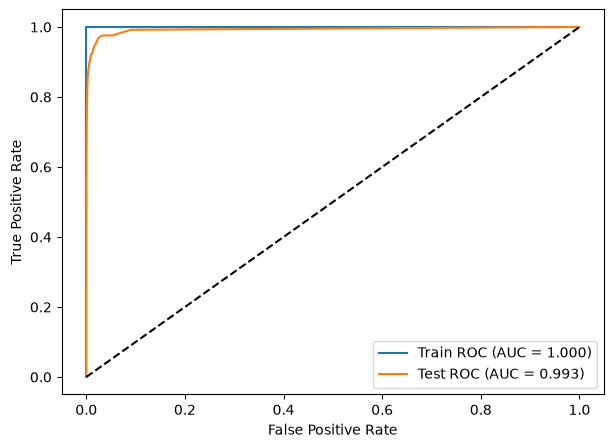

OOB Error: 0.0062


In [13]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    y_tr_prob = model.predict_proba(X_tr)[:, 1]
    y_te_prob = model.predict_proba(X_te)[:, 1]

    print("Train Confusion Matrix:\n", confusion_matrix(y_tr, y_tr_pred))
    print("Test Confusion Matrix:\n", confusion_matrix(y_te, y_te_pred))
    
    print(f"Train Misclassification Error: {1 - accuracy_score(y_tr, y_tr_pred):.4f}")
    print(f"Test Misclassification Error: {1 - accuracy_score(y_te, y_te_pred):.4f}")
    
    auc_tr = roc_auc_score(y_tr, y_tr_prob)
    auc_te = roc_auc_score(y_te, y_te_prob)
    print(f"Train AUC: {auc_tr:.4f}")
    print(f"Test AUC: {auc_te:.4f}")
    
    fpr_tr, tpr_tr, _ = roc_curve(y_tr, y_tr_prob)
    fpr_te, tpr_te, _ = roc_curve(y_te, y_te_prob)
    
    plt.figure(figsize=(7, 5))
    plt.plot(fpr_tr, tpr_tr, label=f"Train ROC (AUC = {auc_tr:.3f})")
    plt.plot(fpr_te, tpr_te, label=f"Test ROC (AUC = {auc_te:.3f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

rf_unweighted = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
rf_unweighted.fit(X_train, y_train)

evaluate_model(rf_unweighted, X_train, y_train, X_test, y_test)
print(f"OOB Error: {1 - rf_unweighted.oob_score_:.4f}")

### (d) Research class imbalance in random forest

Cost-sensitive learning, weighting the impurity split criterion inversely proportional to class frequencies.

Balanced Random Forest, down-sampling the majority class in each bootstrap replicate.

Train Confusion Matrix:
 [[59000     0]
 [    1   999]]
Test Confusion Matrix:
 [[15606    19]
 [  164   211]]
Train Misclassification Error: 0.0000
Test Misclassification Error: 0.0114
Train AUC: 1.0000
Test AUC: 0.9904


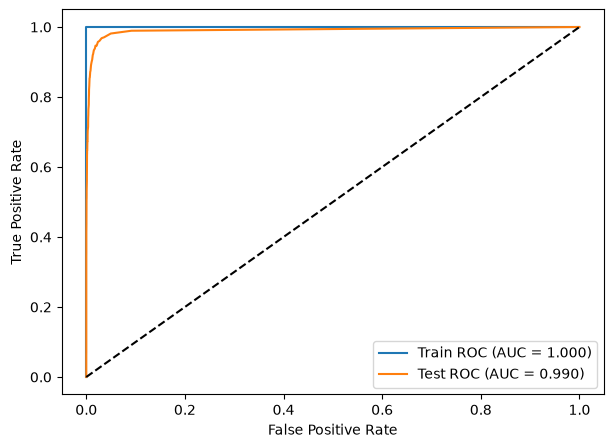

Weighted OOB Error: 0.0080


In [14]:
rf_weighted = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced_subsample', 
    oob_score=True, 
    random_state=42, 
    n_jobs=-1
)
rf_weighted.fit(X_train, y_train)

evaluate_model(rf_weighted, X_train, y_train, X_test, y_test)
print(f"Weighted OOB Error: {1 - rf_weighted.oob_score_:.4f}")

The False Negatives increase from 106 to 164, leading to a total cost increase from 53,150 to 82,190. The Test AUC dropped slightly and Test Error increase slightly. This model's ranking ability remains strong despite threshold shifts

### (e) XGBoost and Model Trees

c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [01:14:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  bst.update(dtrain, iteration=i, fobj=obj)


Best reg_alpha: 0.1
Train Confusion Matrix:
 [[58709   291]
 [  350   650]]
Test Confusion Matrix:
 [[15536    89]
 [  137   238]]
Train Misclassification Error: 0.0107
Test Misclassification Error: 0.0141
Train AUC: 0.8225
Test AUC: 0.8145


c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\core.py:569: UserWarning: [01:14:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  return func(**kwargs)


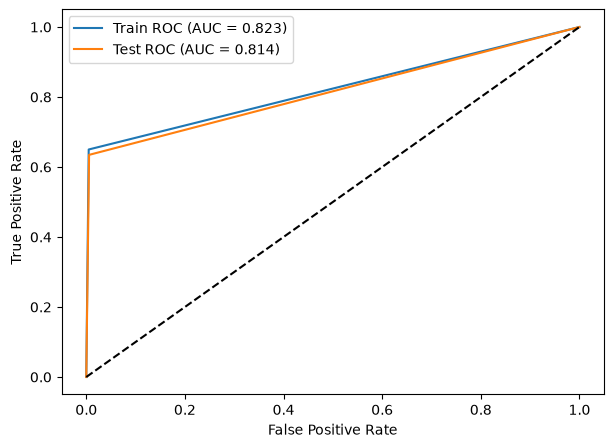

In [16]:
xgb_clf = xgb.XGBClassifier(
    booster='gblinear',
    objective='binary:logistic',
    eval_metric='logloss',
    reg_lambda=0,
    random_state=42
)

param_grid = {'reg_alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_xgb = GridSearchCV(xgb_clf, param_grid, cv=cv_strat, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train, y_train)

print(f"Best reg_alpha: {grid_xgb.best_params_['reg_alpha']}")
evaluate_model(grid_xgb.best_estimator_, X_train, y_train, X_test, y_test)

### (f) Use SMOTE to pre-process your data

c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [01:16:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  bst.update(dtrain, iteration=i, fobj=obj)


Best SMOTE reg_alpha: 10.0
Train Confusion Matrix:
 [[46705 12295]
 [  443   557]]
Test Confusion Matrix:
 [[12384  3241]
 [  174   201]]
Train Misclassification Error: 0.2123
Test Misclassification Error: 0.2134
Train AUC: 0.6743
Test AUC: 0.6643


c:\Users\admins\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\core.py:569: UserWarning: [01:16:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  return func(**kwargs)


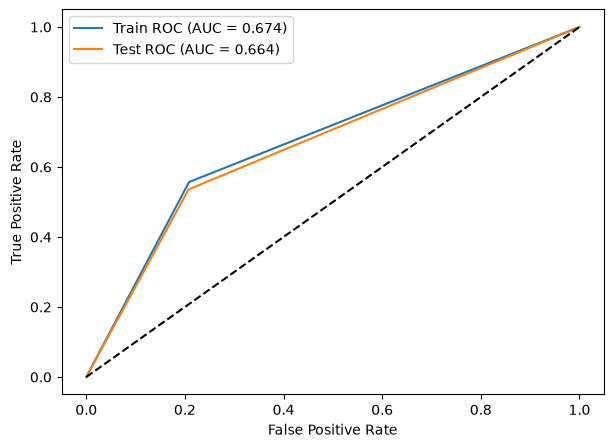

In [17]:
smote_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', xgb.XGBClassifier(
        booster='gblinear', 
        objective='binary:logistic', 
        eval_metric='logloss', 
        reg_lambda=0, 
        random_state=42
    ))
])

grid_smote = GridSearchCV(
    smote_pipe, 
    param_grid={'xgb__reg_alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}, 
    cv=cv_strat, 
    scoring='roc_auc', 
    n_jobs=-1
)
grid_smote.fit(X_train, y_train)

print(f"Best SMOTE reg_alpha: {grid_smote.best_params_['xgb__reg_alpha']}")
evaluate_model(grid_smote.best_estimator_, X_train, y_train, X_test, y_test)

Both error increased and AUC dropped. Cross-validation selected a larger regularization parameter alpha = 10.0 vs 0.1 to aggressively penalize coefficients and combat the massive noise introduced by the synthetic points. This causes the model to underfit, leading to an increase of False Positives and a drop in recall.

## 2. ISLR 6.6.3

(a) Training RSS: (iv) Steadily decreases. As s increases, the feasible parameter constraint region expands monotonically. The unconstrained OLS solution is approached, making training RSS to decrease steadily.

(b) Test RSS: (ii) Decreases initially, and then increases in a U-shape. At s=0, all $\beta_j = 0$. As s increases, model flexibility increases, reducing bias and test RSS until an optimal point, after which variance grows and overfits.

(c) Variance: (iii) Steadily increases. A larger budget s makes coefficients to adapt more aggressively to the particular sample data.

(d) Squared Bias: (iv) Steadily decreases. As s $\to \infty$, the model approaches unconstrained least squares, reducing underfitting.

(e) Irreducible error: (v) Remains constant. The irreducible error $\text{Var}(\epsilon) = \sigma^2$ is an inherent property of the data generation process independent of s.

## 3. ISLR 6.6.5

(a) Ridge Regression Optimization
$\min_{\beta_1, \beta_2} (y_1 - x_1\beta_1 - x_1\beta_2)^2 + (y_2 - x_2\beta_1 - x_2\beta_2)^2 + \lambda(\beta_1^2 + \beta_2^2)$
$Let $A = x_1^2 + x_2^2$ and $C = x_1 y_1 + x_2 y_2$. 

The objective simplifies to $f(\beta_1, \beta_2) = A(\beta_1 + \beta_2)^2 - 2C(\beta_1 + \beta_2) + (y_1^2 + y_2^2) + \lambda(\beta_1^2 + \beta_2^2)$

Taking partial derivatives with respect to $\beta_1$ and $\beta_2$ $\frac{\partial f}{\partial \beta_1} = 2A(\beta_1 + \beta_2) - 2C + 2\lambda\beta_1 = 0$
$\frac{\partial f}{\partial \beta_2} = 2A(\beta_1 + \beta_2) - 2C + 2\lambda\beta_2 = 0$

Subtracting the two equations gives $2\lambda(\beta_1 - \beta_2) = 0$. Since $\lambda > 0$, $\hat{\beta}_1 = \hat{\beta}_2\\$.

(b) Lasso Optimization $\min_{\beta_1, \beta_2} A(\beta_1 + \beta_2)^2 - 2C(\beta_1 + \beta_2) + (y_1^2 + y_2^2) + \lambda(\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{})$

Let $s = \beta_1 + \beta_2$. The squared error term depends on $s$: $g(s) = A s^2 - 2Cs + (y_1^2 + y_2^2)$

For any fixed value of $s > 0$, by triangle inequality:$\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{} \ge \vert{}\beta_1 + \beta_2\vert{} = s$

Equality holds if and only if $\beta_1$ and $\beta_2$ have the same sign. Therefore, any pair $(\beta_1, \beta_2)$ such that $\beta_1 \ge 0, \beta_2 \ge 0$, and $\beta_1 + \beta_2 = s^*$ achieves the same min objective value. The Lasso solution is therefore not unique; any point on the line segment connecting $(s^*, 0)$ and $(0, s^*)$ is an optimal solution.

## 4. ISLR 8.4.5

Majority Vote: Classify each tree's prediction based on whether $\hat{p}_m(X) > 0.5$ (or $\le 0.5$).

Red ($> 0.5$): $0.55, 0.6, 0.6, 0.65, 0.7, 0.75 \implies 6 \text{ trees}$ 

Green ($\le 0.5$): $0.1, 0.15, 0.2, 0.2 \implies 4 \text{ trees}$

Verdict: Red

Average Probability: Compute the mean of all 10 estimated probabilities: $\bar{p} = \frac{0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = \frac{4.9}{10} = 0.49$

Because $\bar{p} = 0.49 < 0.5$, the observation is classified as Green

Verdict: Green

## 5. ISLR 9.7.3

(a) & (b) 

Red closest points $(2,2)$ and $(4,4)$

Blue closest points $(2,1)$ and $(4,3)$

The midpoints between $(2,2)$ and $(2,1)$ is $(2, 1.5)$. between $(4,4)$ and $(4,3)$ is $(4, 3.5)$.

The separating line passes through $(2, 1.5)$ and $(4, 3.5)$:$\text{Slope } m = \frac{3.5 - 1.5}{4 - 2} = 1, \quad \text{Intercept } b = 1.5 - 2 = -0.5$ 

Equation of the maximal margin hyperplane:$X_2 - X_1 + 0.5 = 0 \iff -0.5 + X_1 - X_2 = 0$

(c) Classify as Red ($+1$) if $X_1 - X_2 - 0.5 < 0$. Classify as Blue ($-1$) if $X_1 - X_2 - 0.5 > 0$.

(d) The distance between the two parallel margins $X_2 - X_1 + 0.5 = \pm M$: The margin boundary touching $(2,2)$ is $X_2 - X_1 = 0$; touching $(2,1)$ is $X_2 - X_1 = -1$. The orthogonal margin $M$ is the distance from the hyperplane to either support vector:$M = \frac{\vert{}2 - 2 + 0.5\vert{}}{\sqrt{1^2 + (-1)^2}} = \frac{0.5}{\sqrt{2}} = \frac{1}{2\sqrt{2}} = \frac{\sqrt{2}}{4} \approx 0.3536$

(e) The support vectors are the points lying strictly on the margin boundaries $(2,2)$(Red) $(4,4)$(Red) $(2,1)$(Blue) $(4,3)$(Blue)

(f) Point $x_7 = (4,1)$ is strictly outside the margin on the Blue side $X_2 - X_1 + 0.5 = 1 - 4 + 0.5 = -2.5 < -0.5$

Moving $x_7$ slightly does not alter the boundary because the maximal margin hyperplane is completely determined by the support vectors.

(g) Any hyperplane that separates all points but does not maximize the distance. For example, shifting the intercept $X_2 - X_1 + 0.3 = 0$ or tilting the slope slightly $X_2 - 0.9 X_1 = 0$.

(h) Adding the point $(2, 3)$ with class Blue ($-1$). Notice that the Red points surround it: $(1,4), (2,2), (3,4)$. Point $(2,3)$ falls into the interior of the convex hull of the Red points, making linear separation impossible.